# k-NN vs Voting V2

For V2, I wanted to see if voting would still help when k-NN used more training images. I compared k-NN alone with the vote using the same validation samples.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier, euclidean_distance

result_dir = project_root / 'results/model_comparison'
result_dir.mkdir(parents=True, exist_ok=True)

def save_table(frame, path):
    if path.exists():
        saved = pd.read_csv(path, float_precision='round_trip')
        assert saved.columns.tolist() == frame.columns.tolist()
        assert np.array_equal(saved.to_numpy(), frame.to_numpy())
    else:
        frame.to_csv(path, index=False)

I loaded the image dataset and kept the same seed 42 split, with all 500 features and no normalization.

In [2]:
X, y, _, _ = load_task('image')
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
assert X_train.shape == (16000, 500) and X_val.shape == (4000, 500)

knn8k = pd.read_csv(project_root / 'results/image/knn_v8_validation.csv')
vote8k = pd.read_csv(result_dir / 'image_voted_validation.csv')
nn_predictions = [pd.read_csv(project_root / f'results/image/nn_v{version}_validation.csv')
                  for version in (2, 3, 4)]
for frame in [knn8k, vote8k] + nn_predictions:
    assert len(frame) == 4000 and not frame.isna().any().any()
    assert frame.validation_index.is_unique
    assert np.array_equal(frame.validation_index, np.arange(4000))
    assert np.array_equal(frame.actual_label, y_val)
    for column in ['validation_index', 'actual_label', 'predicted_label']:
        assert pd.api.types.is_integer_dtype(frame[column])
    assert frame.predicted_label.between(0, 49).all()
print('Training shape:', X_train.shape, 'Validation shape:', X_val.shape)

Training shape: (16000, 500) Validation shape: (4000, 500)


I tested k-NN using all 16000 training images and measured the prediction time.

In [3]:
model = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
model.fit(X_train, y_train)
start = perf_counter()
knn16k_predictions = np.asarray(model.predict(X_val))
prediction_time = perf_counter() - start
assert len(knn16k_predictions) == 4000
assert pd.api.types.is_integer_dtype(knn16k_predictions)
assert ((knn16k_predictions >= 0) & (knn16k_predictions <= 49)).all()
knn16k_correct = int((knn16k_predictions == y_val).sum())
knn16k_accuracy = knn16k_correct / len(y_val)
knn16k_validation = pd.DataFrame({'validation_index': np.arange(len(y_val)),
    'actual_label': y_val, 'predicted_label': knn16k_predictions})
save_table(knn16k_validation, result_dir / 'knn_vs_voting_v2_knn16k_validation.csv')
print(f'k-NN 16k: {knn16k_correct}/{len(y_val)}, accuracy={knn16k_accuracy:.5f}')
print(f'Prediction time: {prediction_time:.6f} s')

k-NN 16k: 2077/4000, accuracy=0.51925
Prediction time: 254.742757 s


Then I tried the same vote from V1 with the new k-NN predictions. Ties between leading labels go to k-NN, then NN V4, NN V3 and NN V2.

In [4]:
def vote(prediction_lists, priority_positions):
    if not prediction_lists or len({len(p) for p in prediction_lists}) != 1:
        raise ValueError('Prediction sequences must have identical lengths')
    if sorted(priority_positions) != list(range(len(prediction_lists))):
        raise ValueError('Priority must contain every model position once')
    result = []
    for labels in zip(*prediction_lists):
        counts = Counter(labels)
        maximum = max(counts.values())
        leaders = {label for label, count in counts.items() if count == maximum}
        for position in priority_positions:
            if labels[position] in leaders:
                result.append(int(labels[position]))
                break
    return np.array(result, dtype=int)

priority = [0, 3, 2, 1]
for labels, expected in [([4, 7, 7, 9], 7), ([4, 4, 6, 6], 4),
                         ([1, 2, 3, 4], 1), ([4, 7, 7, 7], 7), ([8, 8, 8, 8], 8)]:
    assert vote([[label] for label in labels], priority).tolist() == [expected]
old_lists = [knn8k.predicted_label.to_numpy()] + [f.predicted_label.to_numpy() for f in nn_predictions]
assert np.array_equal(vote(old_lists, priority), vote8k.predicted_label)
new_lists = [knn16k_predictions] + [f.predicted_label.to_numpy() for f in nn_predictions]
vote16k_predictions = vote(new_lists, priority)
vote16k_correct = int((vote16k_predictions == y_val).sum())
vote16k_accuracy = vote16k_correct / len(y_val)
vote16k_validation = pd.DataFrame({'validation_index': np.arange(len(y_val)),
    'actual_label': y_val, 'predicted_label': vote16k_predictions})
save_table(vote16k_validation, result_dir / 'knn_vs_voting_v2_vote16k_validation.csv')
print(f'Four-model vote with 16k k-NN: {vote16k_correct}/{len(y_val)}, accuracy={vote16k_accuracy:.5f}')

Four-model vote with 16k k-NN: 1930/4000, accuracy=0.48250


I compared both results with the saved k-NN V8 and Voting V1 predictions.

In [5]:
strategies = [
    ('k-NN V8 (8k)', 8000, knn8k.predicted_label.to_numpy(), 'results/image/knn_v8_validation.csv'),
    ('Voting V1 (8k k-NN)', 8000, vote8k.predicted_label.to_numpy(), 'results/model_comparison/image_voted_validation.csv'),
    ('k-NN (16k)', 16000, knn16k_predictions, 'V2 experiment'),
    ('Four-model vote (16k k-NN)', 16000, vote16k_predictions, 'V2 experiment'),
]
rows = []
for name, size, predictions, source in strategies:
    correct = int((predictions == y_val).sum())
    rows.append({'candidate': name, 'training_samples_knn': size, 'correct_count': correct,
                 'validation_samples': len(y_val), 'validation_accuracy': correct / len(y_val),
                 'source': source})
summary = pd.DataFrame(rows)
save_table(summary, result_dir / 'knn_vs_voting_v2_summary.csv')
print(summary.to_string(index=False))
selected_name = 'k-NN (16k)' if knn16k_accuracy >= vote16k_accuracy else 'Four-model vote (16k k-NN)'
selected_accuracy = max(knn16k_accuracy, vote16k_accuracy)
print('Selected image approach:', selected_name)

                 candidate  training_samples_knn  correct_count  validation_samples  validation_accuracy                                              source
              k-NN V8 (8k)                  8000           1585                4000              0.39625                 results/image/knn_v8_validation.csv
       Voting V1 (8k k-NN)                  8000           1763                4000              0.44075 results/model_comparison/image_voted_validation.csv
                k-NN (16k)                 16000           2077                4000              0.51925                                       V2 experiment
Four-model vote (16k k-NN)                 16000           1930                4000              0.48250                                       V2 experiment
Selected image approach: k-NN (16k)


I plotted the accuracies to see which approach worked better.

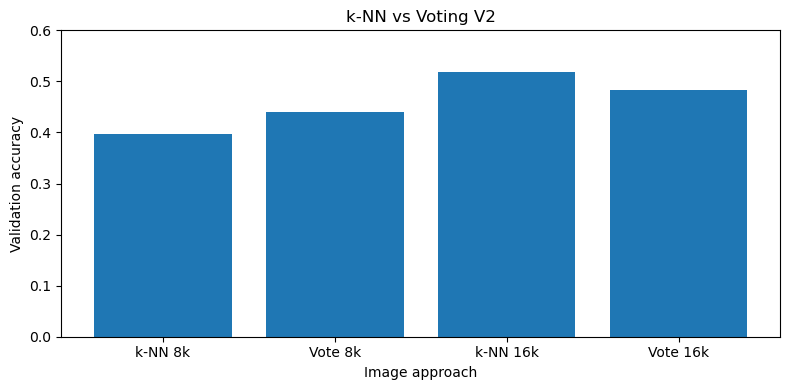

In [6]:
plt.figure(figsize=(8, 4))
plt.bar(['k-NN 8k', 'Vote 8k', 'k-NN 16k', 'Vote 16k'], summary.validation_accuracy)
plt.xlabel('Image approach')
plt.ylabel('Validation accuracy')
plt.title('k-NN vs Voting V2')
plt.ylim(0, 0.6)
plt.tight_layout()
if not (result_dir / 'knn_vs_voting_v2_accuracy.png').exists():
    plt.savefig(result_dir / 'knn_vs_voting_v2_accuracy.png')
plt.show()

I kept NN V3 for sentiment and calculated the combined validation accuracy.

In [7]:
sentiment = pd.read_csv(project_root / 'results/sentiment/nn_v3_validation.csv')
raw_sentiment_labels = pd.read_csv(project_root / 'data/raw/sentiment_train.csv', usecols=['label']).label.to_numpy()
_, _, _, sentiment_y_val = split_train_val(
    np.arange(len(raw_sentiment_labels)).reshape(-1, 1), raw_sentiment_labels,
    val_fraction=0.2, seed=42)
assert len(sentiment) == 2400 and not sentiment.isna().any().any()
assert sentiment.validation_index.is_unique
assert np.array_equal(sentiment.validation_index, np.arange(2400))
assert np.array_equal(sentiment.actual_label, sentiment_y_val)
for column in ['validation_index', 'actual_label', 'predicted_label']:
    assert pd.api.types.is_integer_dtype(sentiment[column])
assert sentiment.predicted_label.between(0, 2).all()
sentiment_correct = int((sentiment.predicted_label == sentiment.actual_label).sum())
sentiment_accuracy = sentiment_correct / len(sentiment)
combined_accuracy = (selected_accuracy + sentiment_accuracy) / 2
print(f'NN V3 sentiment: {sentiment_correct}/{len(sentiment)}, accuracy={sentiment_accuracy!r}')
print('Combined validation accuracy:', combined_accuracy)

NN V3 sentiment: 1639/2400, accuracy=0.6829166666666666
Combined validation accuracy: 0.6010833333333333


I used the selected k-NN settings with all 20000 training images to predict the test labels.

In [11]:
image_X_train, image_y_train, image_X_test, image_test_ids = load_task('image')
assert image_X_train.shape == (20000, 500)
assert image_y_train.shape == (20000,)
assert image_X_test.shape == (5000, 500)
assert len(image_test_ids) == 5000

image_clf = KNNClassifier(k=1, distance_fn=euclidean_distance, voting_method='majority')
image_clf.fit(image_X_train, image_y_train)
start = perf_counter()
image_test_predictions = np.asarray(image_clf.predict(image_X_test))
image_prediction_time = perf_counter() - start
assert len(image_test_predictions) == 5000
assert pd.api.types.is_integer_dtype(image_test_predictions)
assert ((image_test_predictions >= 0) & (image_test_predictions <= 49)).all()
print(f'Image: predicted {len(image_test_predictions)} test labels in {image_prediction_time:.6f} s')

Image: predicted 5000 test labels in 467.726308 s


Finally, I combined the image predictions with NN V3 sentiment and saved them in the Kaggle submission format.

In [12]:
sample = pd.read_csv(project_root / 'data/raw/sample_submission.csv')
text_ids = pd.read_csv(project_root / 'data/raw/sentiment_test.csv', usecols=['id']).id
assert sample.columns.tolist() == ['id', 'label']
assert len(sample) == 10000 and sample.id.is_unique and not sample.isna().any().any()
assert len(text_ids) == 5000 and text_ids.is_unique
assert len(set(image_test_ids)) == 5000
assert all(str(sample_id).startswith('img_') for sample_id in image_test_ids)
assert text_ids.str.startswith('text_').all()
assert set(image_test_ids).isdisjoint(set(text_ids))
assert set(sample.id) == set(image_test_ids) | set(text_ids)
is_image = sample.id.isin(image_test_ids)
is_text = sample.id.isin(text_ids)
assert is_image.sum() == is_text.sum() == 5000

nn3_test = pd.read_csv(project_root / 'submission/nn/submission_v3_nn.csv')
assert nn3_test.columns.tolist() == ['id', 'label']
assert len(nn3_test) == 10000 and nn3_test.id.is_unique
assert set(nn3_test.id) == set(sample.id) and not nn3_test.isna().any().any()
sentiment_predictions = nn3_test.loc[nn3_test.id.isin(text_ids), ['id', 'label']].copy()
assert len(sentiment_predictions) == 5000
assert pd.api.types.is_integer_dtype(sentiment_predictions.label)
assert sentiment_predictions.label.between(0, 2).all()
image_predictions = pd.DataFrame({'id': image_test_ids, 'label': image_test_predictions})
predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
assert len(predictions) == 10000 and predictions.id.is_unique
assert set(predictions.id) == set(sample.id)
submission = sample[['id']].merge(predictions, on='id', how='left', sort=False, validate='one_to_one')
assert submission.columns.tolist() == ['id', 'label']
assert submission.id.tolist() == sample.id.tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission.label)
assert submission.loc[is_image, 'label'].between(0, 49).all()
assert submission.loc[is_text, 'label'].between(0, 2).all()

submission_dir = project_root / 'submissions'
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'submission_knn_vs_voting_v2.csv'
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert saved_submission.equals(submission)
print('Saved', len(saved_submission), 'predictions to', submission_path.relative_to(project_root))

Saved 10000 predictions to submissions\submission_knn_vs_voting_v2.csv


I compared the generated predictions with the earlier k-NN image predictions, the combined submission and Voting V1.

In [13]:
def align_submission(path):
    frame = pd.read_csv(path)
    assert frame.columns.tolist() == ['id', 'label']
    assert len(frame) == 10000 and frame.id.is_unique and not frame.isna().any().any()
    assert set(frame.id) == set(sample.id)
    assert pd.api.types.is_integer_dtype(frame.label)
    aligned = sample[['id']].merge(frame, on='id', how='left', sort=False, validate='one_to_one')
    assert aligned.id.tolist() == sample.id.tolist()
    assert aligned.loc[is_image, 'label'].between(0, 49).all()
    assert aligned.loc[is_text, 'label'].between(0, 2).all()
    return aligned

previous_knn = align_submission(project_root / 'submission/knn/submission_final_knn.csv')
assert np.array_equal(submission.loc[is_image, 'label'], previous_knn.loc[is_image, 'label'])
previous_combined = align_submission(project_root / 'submission/nn/submission_final_nn.csv')
assert submission.equals(previous_combined)
print('Generated predictions match the earlier combined submission.')
voting_v1_path = project_root / 'submissions/submission_knn_nn_voting_v1.csv'
if voting_v1_path.exists():
    voting_v1 = align_submission(voting_v1_path)
    changed = submission.label != voting_v1.label
    print('Image predictions changed from Voting V1:', int((changed & is_image).sum()))
    print('Sentiment predictions changed from Voting V1:', int((changed & is_text).sum()))

Generated predictions match the earlier combined submission.
Image predictions changed from Voting V1: 1878
Sentiment predictions changed from Voting V1: 0


Using 16000 training images improved k-NN to 51.925% accuracy. The vote reached 48.25%, so it did not help this time. I kept k-NN alone for images and NN V3 for sentiment, giving a combined validation accuracy of 60.108%.